@author: Octavio Gutiérrez de Código Máquina 

URL del canal: https://www.youtube.com/CodigoMaquina 

URL del video: https://youtu.be/343XPoh5q_Q

<h1 style="color:purple"> Cálculo de Intervalo de Confianza</h1>

## ¿Qué tiene que ver con la inferencia?
La **inferencia** es usar los datos de un grupo pequeño para aprender algo sobre un grupo más grande. Por ejemplo, podemos medir a 100 personas para estimar la altura promedio de todas las personas de una ciudad, sin tener que medirlas a todas.

El promedio de esas 100 personas es una **estimación**: si elegimos otras 100, el resultado probablemente cambiará un poco. El **intervalo de confianza** muestra un rango de valores razonables para el promedio del grupo completo. En esta libreta, el rango del 95% es aproximadamente **168,1 a 170,8 cm**.

### ¿Cómo se construye?
1. Se calcula el promedio de la muestra: es el centro del rango.
2. Se mide cuánto varían las alturas. Como usamos una muestra, también hay duda sobre el promedio.
3. Se usa el nivel elegido (95%) para calcular qué tan lejos poner los dos límites.

### ¿Qué significa el 95%?
El 95% se elige antes de hacer el cálculo; no quiere decir que el 95% de los datos estén dentro del intervalo. Si tomáramos muchas muestras al azar y calculáramos un intervalo cada vez, alrededor de 95 de cada 100 incluirían el promedio real del grupo completo, siempre que el método sea adecuado para los datos. En el código, `confidence=0.95` pide justamente ese nivel.

### ¿Por qué un intervalo puede ser más ancho o más angosto?
- **Más ancho:** abarca más valores y expresa más duda sobre dónde está el promedio exacto. Pedir 99% de confianza suele hacerlo más ancho que pedir 95%.
- **Más angosto:** abarca menos valores y da una estimación más precisa, pero con menor nivel de confianza (por ejemplo, 90%).
- También influye la muestra: más datos suelen dar un intervalo más angosto; datos muy distintos entre sí suelen darlo más ancho.

Ejemplo: si estimamos que la espera promedio en una fila está entre **4,8 y 5,6 minutos** con un nivel del 95%, ese rango es nuestra estimación para el promedio de todos los clientes. No significa que el 95% de los clientes espere entre 4,8 y 5,6 minutos.

**En esta libreta:** el intervalo de **168,1 a 170,8 cm** estima el promedio de alturas de todo el grupo. No dice que el 95% de las personas mida entre esos valores.

En la vida diaria sería como medir cuánto esperan 100 clientes en una fila para estimar la espera promedio de todos los clientes. No sabemos el promedio exacto de todos, pero la muestra y el intervalo nos dan una estimación con un margen de duda.

In [ ]:
import numpy as np  # Sirve para trabajar con muchos números y calcular promedios.
import scipy.stats as stats  # Sirve para hacer cálculos estadísticos.
from math import sqrt  # Trae la función para calcular la raíz cuadrada.

# Estos datos son alturas de 100 personas (en centímetros).
# Muestra de 100 personas con media de 170 cm y desv est de 8
# alturas = np.round(np.random.normal(170, 8, 100), 1)

alturas = np.array([174.4, 171.1, 160.4, 166.1, 173.0, 163.5,
                     150.5, 169.3, 177.9, 167.5, 157.4, 165.3,
                     161.2, 170.1, 175.8, 167.8, 172.7, 160.8, 
                     182.5, 165.9, 162.4, 164.1, 181.2, 166.0,
                     176.8, 176.1, 172.5, 173.3, 169.0, 171.6,
                     163.1, 171.3, 168.5, 158.0, 169.1, 173.3,
                     165.7, 166.5, 163.1, 167.2, 180.6, 175.2,
                     154.8, 180.1, 164.3, 161.2, 178.8, 171.6,
                     160.7, 171.6, 176.2, 172.7, 171.3, 176.9,
                     182.5, 170.4, 175.8, 164.6, 168.3, 167.6,
                     160.8, 175.9, 169.2, 166.8, 171.4, 168.0,
                     173.7, 169.8, 176.5, 166.0, 161.6, 164.8,
                     173.6, 166.9, 168.2, 171.2, 156.0, 171.7,
                     168.2, 177.7, 169.7, 179.2, 179.9, 175.7,
                     165.1, 173.8, 168.2, 166.6, 178.7, 158.6,
                     175.6, 161.0, 157.5, 169.8, 183.1, 164.3,
                     180.1, 167.6, 165.2, 167.9])

# Un intervalo de confianza calcula un rango probable para el promedio real de una población a partir de una muestra.
# El PORCENTAJE elegido (ej. 95%) determina qué porción de la campana de Gauss cubres mediante su multiplicador (z):
# un porcentaje más alto usa un 'z' mayor y ensancha el intervalo (más seguridad de acertar, menos precisión),
# mientras que un porcentaje más bajo usa un 'z' menor y lo estrecha (más precisión, mayor riesgo de que el valor real quede fuera).
# cada porcentaje tiene un valor de 'z' asociado, que se puede calcular con la función stats.norm.ppf(). 
# basado en la campana de Gauss
# Fórmula para el intervalo de confianza: promedio ± z * (desv est / √n), donde n es el tamaño de la muestra.

print("\nIntervalo de Confianza con un nivel de 95%\n")  # Vamos a mostrar el rango estimado para el promedio.
print(stats.norm.interval(confidence=0.95,  # Pide un intervalo del 95%.
                     loc=np.mean(alturas),  # loc es el centro: el promedio de las 100 alturas.
                     scale=alturas.std(ddof=1) / sqrt(alturas.size)))  # scale es el margen de variación del promedio.

# La misma cuenta, escrita paso a paso: promedio menos y más 1,96 veces el margen.
print((alturas.mean() - 1.960 * (alturas.std(ddof=1) / sqrt(alturas.size)),
       alturas.mean() + 1.960 * (alturas.std(ddof=1) / sqrt(alturas.size))))

# sqrt(alturas.size)= es la raíz cuadrada del tamaño de la muestra, 
# que se usa para calcular el margen de error del promedio.
# ddof=1 indica que se usa la desviación estándar muestral (n-1)
#  en lugar de la poblacional (n).




print("\nValor que se usa para cada nivel de confianza\n")
#stats.norm.ppf() calcula el valor de z que corresponde a un nivel de confianza dado.
print("90%:", stats.norm.ppf(1 - (1 - 0.90)/2))  
print("95%:", stats.norm.ppf(1 - (1 - 0.95)/2))  
print("99%:", stats.norm.ppf(1 - (1 - 0.99)/2))  


Intervalo de Confianza con un nivel de 95%

(np.float64(168.10070315393247), np.float64(170.75529684606752))
(np.float64(168.1006787640933), np.float64(170.7553212359067))

Valor que se usa para cada nivel de confianza

90%: 1.6448536269514722
95%: 1.959963984540054
99%: 2.5758293035489004


<br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br>
<h1 style="color:purple"> Graficar Intervalo de Confianza</h1>

Este gráfico compara las alturas promedio de dos grupos inventados para practicar. La barra muestra el promedio de cada grupo y las rayitas en los extremos muestran el intervalo estimado. No muestran las alturas mínima y máxima de las personas. Un intervalo del 99% suele ser más ancho que uno del 95% porque intenta dar más seguridad.

C:\Users\mcast\AppData\Local\Temp\ipykernel_656\3756801294.py:15: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 99)` for the same effect.

  grafica = sns.barplot(data=alturas, ci=99, capsize=0.20)


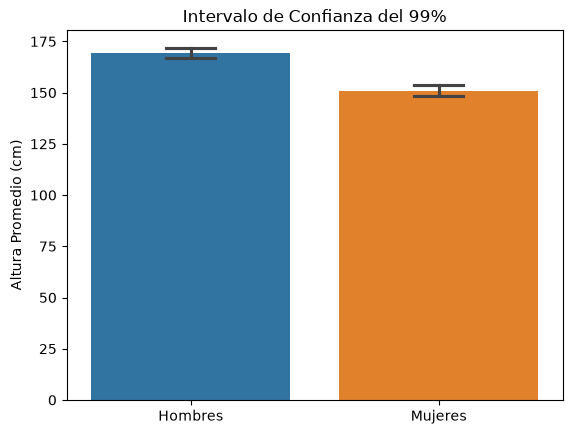

In [17]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

alturas = pd.DataFrame()

# Muestras de 100 hombres y 100 mujeres
alturas["Hombres"] = np.round(np.random.normal(170, 10, 100), 1)
alturas["Mujeres"] = np.round(np.random.normal(150, 10, 100), 1)
# np.random.normal() genera números aleatorios con distribución
#   normal (campana de Gauss) con media y desviación estándar dadas.
# 10 es la desviación estándar, que indica qué tan dispersos están los datos alrededor de la media.
# 100 es el tamaño de la muestra, que indica cuántos datos se generan.

grafica = sns.barplot(data=alturas, ci=99, capsize=0.20)
# sns.barplot() dibuja un gráfico de barras con los promedios 
#    de cada columna y sus intervalos de confianza.
# ci= 99 indica que se dibuja un intervalo de confianza del 99%
#    alrededor de cada barra.
# capsize=0.20 longitud del ancho del dibujo de los intervalos
grafica.set(title="Intervalo de Confianza del 99%", 
            ylabel="Altura Promedio (cm)")
plt.show()



<br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br><br>
